# Módulo 3 — Grafo de entidades y relaciones

**Proyecto:** Observatorio del discurso presidencial en español
**Unidades del temario:** EI 3.3 (reconocimiento de entidades, identificación y clasificación de
nombres) y EI 3.5 (extracción de relaciones)

El módulo convierte los 4,531 discursos en un **grafo de entidades** con relaciones tipadas y
evidencia textual. Todo simbólico: gazetteers escritos a mano, un autómata Aho-Corasick
(reutilizado del módulo de EI), expresiones regulares, reglas de coreferencia y un patrón
sujeto–verbo–objeto para las relaciones verbales.

```
discurso
  │
  ├─ segmentación y tokenización (reutiliza ei_scripts.segment)
  │
  ├─ MENCIONES
  │   1. gazetteer (personas / organizaciones / lugares) vía Aho-Corasick
  │   2. cabeceras de organización ("Secretaría de la Defensa")
  │   3. rachas de mayúsculas -> nombres propios nuevos
  │   4. siglas (IMSS) y acrónimos
  │
  ├─ COREFERENCIA (4 reglas)
  │   hablante · cargo->ocupante · sigla<->expansión · elipsis con nombre
  │
  ├─ RELACIONES
  │   coocurrencia en ventana (recall) + sujeto-verbo-objeto (precisión) + cargo
  │
  └─ GRAFO (NetworkX): nodos con tipo/mentions/docs, aristas tipadas con peso y evidencia
```

Cada mención conserva su **span de caracteres** en el discurso, su tipo (`PER`, `ORG`, `LOC`,
`CARGO`) y el nodo canónico al que se resuelve, de modo que toda arista se puede auditar contra
la oración que la origina.

## 0. Preparación

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "er_scripts").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from ei_scripts.segment import segment, tokenize
from er_scripts import config, lexicon
from er_scripts.coref import resolve
from er_scripts.graph import EntityGraph
from er_scripts.mentions import EntityDetector, _name_runs, canonical_label, node_type
from er_scripts.relations import RelationAggregator, relations_of
from ri_scripts.corpus import read_doc

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.figsize"] = (9, 3.6)

print("artefactos del módulo:")
for path in sorted(config.ARTIFACTS.glob("*")):
    print(f"  {path.name:26s} {path.stat().st_size / 1e6:8.2f} MB")

artefactos del módulo:
  eval.json                      0.01 MB
  graph.graphml                 15.59 MB
  graph.json                    10.71 MB
  mentions_by_doc.jsonl         35.11 MB
  relations.jsonl               15.57 MB
  stats.json                     0.03 MB
  tables.md                      0.00 MB


## 1. Gazetteers: el léxico como conocimiento

El gazetteer es la única "base de conocimiento" del módulo y es explícito:

* **personas** — mandatarios, gabinetes, opositores y figuras internacionales, con alias
  (`AMLO`, `el tabasqueño`, `CFK`, `Zapatero`, …);
* **organizaciones** — por sigla (`IMSS`, `OTAN`) y por nombre completo, más un mapa
  sigla ↔ expansión que se usa para fusionar ambos nodos;
* **lugares** — topónimos de los cinco países, con su forma de superficie (`México`, `España`).

Sobre ese léxico se construye un Aho-Corasick, igual que en el módulo de EI, con 658 patrones de entidad
(personas, organizaciones y lugares) en vez de disparadores de promesa.

In [2]:
from er_scripts.mentions import automaton

ac = automaton()
print("autómata de entidades:", ac.stats())
print()
print("patrones por tipo:", dict(Counter(t[0] for t in ac.tags)))
print("personas en el gazetteer:", len({c for (k, c) in lexicon.PERSONS.items()}), "(con alias)")
print("organizaciones:", len(lexicon.ORGS), "· lugares:", len(lexicon.PLACES))
print()
print("ejemplos de alias -> canónico:")
for seq in [("amlo",), ("el", "tabasqueno"), ("cfk",), ("zapatero",)]:
    if seq in lexicon.PERSONS:
        print(f"  {' '.join(seq):18s} -> {lexicon.PERSONS[seq]}")

autómata de entidades: {'estados': 1019, 'patrones': 658, 'aristas': 1018, 'alfabeto': 721, 'profundidad_max': 11}

patrones por tipo: {'PER': 383, 'ORG': 136, 'LOC': 139}
personas en el gazetteer: 216 (con alias)
organizaciones: 136 · lugares: 139

ejemplos de alias -> canónico:
  amlo               -> Andrés Manuel López Obrador
  cfk                -> Cristina Fernández de Kirchner
  zapatero           -> José Luis Rodríguez Zapatero


## 2. Menciones: tres capas y sus reglas de rechazo

**Capa 1 — gazetteer.** Lo que está en la lista se detecta con su nodo canónico. Dos filtros de
precisión importantes:

* las personas exigen **mayúscula inicial** (si no, `maduro` el adjetivo se confundiría con
  Maduro el presidente) y las organizaciones también (`ciudadanos`, `podemos`, `firma` son
  palabras comunes);
* un **apellido suelto** del gazetteer no se acepta si está pegado a otra palabra capitalizada
  (`… Rodríguez Vallejo` no debe producir "Vallejo" -> Camila Vallejo).

**Capa 2 — patrones.** Rachas de palabras capitalizadas (con conectores `de`, `del`, `la`), con
una lista negra de arranques que nunca inician un nombre (`El`, `Pero`, `Hoy`, meses, cargos) y
de secuencias que se leen como persona y no lo son (`Tren Maya`, `América Latina`).

**Capa 3 — siglas.** Token todo en mayúsculas de 2 a 12 caracteres: `IMSS`, `CFE`, `OTAN`,
`CESFAM`.

In [3]:
texto = ("El director del IMSS, Zoé Robledo, y el secretario de Hacienda visitaron Tijuana. "
         "El gobierno de México firmó un convenio con Iberdrola y con la CFE. "
         "Luego el presidente habló con Emmanuel Macron y con la ministra de Defensa.")
doc = {"doc_id": 0, "speaker": "Andrés Manuel López Obrador", "country": "MEX", "date": "2022-06-21"}

filas = []
for sent in segment(texto):
    for m in resolve(sent, EntityDetector().detect(sent, doc["doc_id"]), doc):
        filas.append({
            "oración": sent.text[:46] + "…",
            "tipo": m.type,
            "superficie": m.surface,
            "nodo": m.resolved or m.canonical,
            "fuente": m.source,
        })
pd.DataFrame(filas)

,oración,tipo,superficie,nodo,fuente
0,"El director del IMSS, Zoé Robledo, y el secret…",CARGO,director del IMSS,PER:Zoé Robledo,cargo_explicito
1,"El director del IMSS, Zoé Robledo, y el secret…",ORG,IMSS,ORG:IMSS,gazetteer
2,"El director del IMSS, Zoé Robledo, y el secret…",PER,Zoé Robledo,PER:Zoé Robledo,gazetteer
3,"El director del IMSS, Zoé Robledo, y el secret…",CARGO,secretario de Hacienda,PER:Rogelio Ramírez de la O,cargo_inferido
4,"El director del IMSS, Zoé Robledo, y el secret…",LOC,Tijuana,LOC:Tijuana,gazetteer
5,El gobierno de México firmó un convenio con Ib…,ORG,El gobierno,ORG:Gobierno de México,coref
6,El gobierno de México firmó un convenio con Ib…,LOC,México,LOC:México,gazetteer
7,El gobierno de México firmó un convenio con Ib…,ORG,Iberdrola,ORG:Iberdrola,gazetteer
8,El gobierno de México firmó un convenio con Ib…,ORG,CFE,ORG:CFE,gazetteer
9,Luego el presidente habló con Emmanuel Macron …,PER,el presidente,PER:Andrés Manuel López Obrador,coref


In [4]:
# Las rachas de mayúsculas que alimentan la capa de patrones
ejemplo = "El gobernador de Guanajuato, Diego Sinhue Rodríguez Vallejo, recibió a los alcaldes."
words = [t for t in tokenize(ejemplo) if t.is_word]
for run in _name_runs(words):
    print(f"{' '.join(words[i].surface for i in run):40s}  (tokens {run[0]}-{run[-1]})")

El                                        (tokens 0-0)
Guanajuato Diego Sinhue Rodríguez Vallejo  (tokens 3-7)


## 3. Coreferencia por reglas

Cuatro reglas, cada una con su justificación y su límite:

| Regla | Patrón | Resuelve a |
|---|---|---|
| 1. Hablante | `el presidente`, `el mandatario`, `el Ejecutivo` (artículo 1ª persona) | el hablante del discurso |
| 1b. Gobierno | `el gobierno`, `mi gobierno`, `el gobierno de Chile` | `ORG:Gobierno de <país>` |
| 2. Cargo → ocupante | `el secretario de Hacienda` | el ocupante de la tabla estática |
| 3. Sigla ↔ expansión | `Instituto Mexicano del Seguro Social` | `ORG:IMSS` |
| 4. Nombre adyacente | `el presidente Boric` | manda el nombre propio (no el hablante) |

Se distingue el cargo **explícito** (`el secretario de Hacienda, Rogelio Ramírez`, con el nombre
al lado) del **inferido** (sólo aparece el cargo y el ocupante sale de la tabla): son relaciones
distintas porque la segunda es una inferencia, no una afirmación del discurso.

In [5]:
pruebas = [
    ("MEX", "El presidente anunció que el gobierno de México invertirá en el sureste."),
    ("MEX", "El director del IMSS, Zoé Robledo, presentó el informe."),
    ("MEX", "El secretario de Hacienda informó sobre el presupuesto."),
    ("ESP", "El presidente del Gobierno compareció ante el Congreso."),
    ("MEX", "El presidente Boric visitó la región y habló del IMSS."),
    ("VEN", "El Instituto Venezolano de los Seguros Sociales y el Seguro Social atienden a la población."),
]
filas = []
for country, texto in pruebas:
    meta = {"doc_id": 0, "country": country, "speaker": {"MEX": "Andrés Manuel López Obrador",
            "ESP": "Pedro Sánchez", "VEN": "Nicolás Maduro", "ARG": "Javier Milei",
            "CHL": "Sebastián Piñera Echenique"}[country]}
    for sent in segment(texto):
        for m in resolve(sent, EntityDetector().detect(sent, 0), meta):
            filas.append({"país": country, "superficie": m.surface, "tipo": m.type,
                          "resuelve a": m.resolved or m.canonical, "regla": m.source})
pd.DataFrame(filas)

,país,superficie,tipo,resuelve a,regla
0,MEX,El presidente,PER,PER:Andrés Manuel López Obrador,coref
1,MEX,el gobierno,ORG,ORG:Gobierno de México,coref
2,MEX,México,LOC,LOC:México,gazetteer
3,MEX,director del IMSS,CARGO,PER:Zoé Robledo,cargo_explicito
4,MEX,IMSS,ORG,ORG:IMSS,gazetteer
5,MEX,Zoé Robledo,PER,PER:Zoé Robledo,gazetteer
6,MEX,secretario de Hacienda,CARGO,PER:Rogelio Ramírez de la O,cargo_inferido
7,ESP,El presidente del Gobierno,PER,PER:Pedro Sánchez,gazetteer
8,MEX,Boric,PER,PER:Gabriel Boric,gazetteer
9,MEX,IMSS,ORG,ORG:IMSS,gazetteer


## 4. Relaciones

**Coocurrencia en ventana.** Toda pareja de entidades distintas a menos de
`COOC_WINDOW = 12` tokens genera `coocurre`. Con `m` entidades únicas por oración (tope 10) son
a lo más `m(m−1)/2 = 45` pares, así que el coste es lineal en el número de oraciones.

**Patrón verbal.** Para cada verbo relacional del léxico se toma la entidad más cercana a la
izquierda (sujeto) y a la derecha (objeto):

$$\text{sujeto} \xrightarrow{\text{verbo}} \text{objeto} \quad\Rightarrow\quad
(a, \text{tipo}(v), b)$$

Las formas verbales se generan por regla morfológica (3ª persona y 1ª plural) porque el **stem
confunde sustantivo con verbo**: `el apoyo` y `apoyó` comparten stem, y con el stem aparecerían
"apoyos" por todas partes.

**Cargo.** Si el cargo se resolvió a una persona y dentro de su span hay una organización
(`director del IMSS`), se emite `ocupa_cargo` (explícito) o `cargo_inferido`.

In [6]:
from er_scripts.relations import VERB_FORMS

print("formas verbales reconocidas:", len(VERB_FORMS))
print("el sustantivo 'apoyo' no se confunde con el verbo:", "apoyo" not in VERB_FORMS)
print("el verbo 'apoyaron' sí:", VERB_FORMS.get("apoyaron"))
print("ejemplos:", {f: VERB_FORMS[f] for f in ["firmo", "reunio", "exigio", "inauguraron"]
                    if f in VERB_FORMS})

formas verbales reconocidas: 222
el sustantivo 'apoyo' no se confunde con el verbo: True
el verbo 'apoyaron' sí: apoya
ejemplos: {'firmo': 'firma_con', 'reunio': 'se_reune_con', 'exigio': 'exige_a', 'inauguraron': 'inaugura'}


In [7]:
ejemplos = [
    "El secretario de Hacienda visitó Tijuana y entregó apoyos al IMSS.",
    "Pedro Sánchez y Emmanuel Macron firmaron un acuerdo con la Unión Europea.",
    "La CFE acusó a Iberdrola de prácticas monopólicas en España.",
]
for texto in ejemplos:
    meta = {"doc_id": 0, "country": "MEX", "speaker": "Andrés Manuel López Obrador"}
    for sent in segment(texto):
        ms = resolve(sent, EntityDetector().detect(sent, 0), meta)
        print(texto)
        for m in ms:
            print(f"   {m.type:5s} {m.surface[:30]:32s} -> {m.resolved or m.canonical}")
        for occ in relations_of(sent, ms, meta):
            print(f"   REL {occ.a} --{occ.type}--> {occ.b}")
        print()

El secretario de Hacienda visitó Tijuana y entregó apoyos al IMSS.
   CARGO secretario de Hacienda           -> PER:Rogelio Ramírez de la O
   LOC   Tijuana                          -> LOC:Tijuana
   ORG   IMSS                             -> ORG:IMSS
   REL PER:Rogelio Ramírez de la O --coocurre--> LOC:Tijuana
   REL PER:Rogelio Ramírez de la O --coocurre--> ORG:IMSS
   REL LOC:Tijuana --coocurre--> ORG:IMSS

Pedro Sánchez y Emmanuel Macron firmaron un acuerdo con la Unión Europea.
   PER   Pedro Sánchez                    -> PER:Pedro Sánchez
   PER   Emmanuel Macron                  -> PER:Emmanuel Macron
   ORG   Unión Europea                    -> ORG:Unión Europea
   REL PER:Pedro Sánchez --coocurre--> PER:Emmanuel Macron
   REL PER:Pedro Sánchez --coocurre--> ORG:Unión Europea
   REL PER:Emmanuel Macron --coocurre--> ORG:Unión Europea
   REL PER:Emmanuel Macron --firma_con--> ORG:Unión Europea

La CFE acusó a Iberdrola de prácticas monopólicas en España.
   ORG   CFE             

## 5. El grafo: agregación y métricas

Las ocurrencias se agregan por arista `(a, b, tipo)` con **peso** = número de ocurrencias,
documentos de evidencia y hasta 3 oraciones de muestra. Para las métricas se proyecta a un grafo
**no dirigido ponderado** y se calculan:

* densidad $D = \frac{2|E|}{|V|(|V|-1)}$,
* grado y grado ponderado,
* intermediación (betweenness, aproximada por muestreo con `k = 64`),
* comunidades por modularidad voraz y la modularidad resultante
  $Q = \frac{1}{2m}\sum_{ij}\left[A_{ij} - \frac{k_i k_j}{2m}\right]\delta(c_i, c_j)$.

Las métricas se calculan sobre los **nodos conectados**: la mayoría de las entidades aparece una
sola vez y un nodo aislado distorsiona densidad y modularidad.

In [8]:
stats = json.loads((config.ARTIFACTS / "stats.json").read_text(encoding="utf-8"))
print("opciones:", stats["opciones"])
print("volumen:", stats["volumen"])
print("cobertura:", stats["cobertura"])
print("menciones:", stats["menciones"])

opciones: {'patterns': True, 'coref': True, 'min_weight': 2, 'limit': 0}
volumen: {'documentos': 4531, 'oraciones': 993494, 'menciones': 643811, 'relaciones_ocurrencias': 257063, 'segundos': 211.1}
cobertura: {'oraciones_con_entidades': 371705, 'oraciones_sin_entidades': 621789, 'oraciones_con_relaciones': 115191, 'pct_oraciones_con_entidades': 37.41}
menciones: {'por_tipo': {'PER': 231466, 'LOC': 214522, 'ORG': 158992, 'CARGO': 38831}, 'por_fuente': {'gazetteer': 380300, 'nombre': 174736, 'cargo_de': 38831, 'coref': 24587, 'sigla': 20101, 'cargo_inferido': 4643, 'cargo_explicito': 613}, 'elípticas_por_coref': 24587}


In [9]:
pd.DataFrame(stats["entidades"]["top_menciones"]).head(15)

,nodo,label,tipo,menciones,docs
0,PER:Andrés Manuel López Obrador,Andrés Manuel López Obrador,PER,56064,2298
1,LOC:México,México,LOC,39538,2371
2,LOC:España,España,LOC,18639,1873
3,CARGO:secretario,secretario,CARGO,16034,2075
4,LOC:Estados Unidos,Estados Unidos,LOC,15652,2224
5,ORG:Gobierno de México,Gobierno de México,ORG,11186,1942
6,CARGO:presidente,presidente,CARGO,7011,2503
7,ORG:Guardia Nacional,Guardia Nacional,ORG,6793,1186
8,ORG:Gobierno de España,Gobierno de España,ORG,6657,932
9,ORG:PEMEX,PEMEX,ORG,6612,1091


In [10]:
resumen = {k: v for k, v in stats["grafo"].items() if not isinstance(v, list)}
pd.Series(resumen).to_frame("valor")

,valor
nodos_totales,46869.000000
nodos_aislados,42724.000000
nodos_conectados,4145.000000
nodos,4145.000000
aristas_proyectadas,14052.000000
aristas_tipadas,18659.000000
densidad,0.001636
componentes_conexas,186.000000
componente_gigante,0.080000
grado_medio,6.780000


In [11]:
pd.DataFrame(stats["grafo"]["top_grado"]).head(12)

,nodo,label,tipo,grado
0,PER:Andrés Manuel López Obrador,Andrés Manuel López Obrador,PER,633
1,LOC:México,México,LOC,620
2,CARGO:secretario,secretario,CARGO,542
3,CARGO:presidente,presidente,CARGO,486
4,ORG:Gobierno de México,Gobierno de México,ORG,456
5,CARGO:general,general,CARGO,417
6,LOC:España,España,LOC,371
7,LOC:Estados Unidos,Estados Unidos,LOC,350
8,LOC:Ciudad de México,Ciudad de México,LOC,264
9,CARGO:director,director,CARGO,243


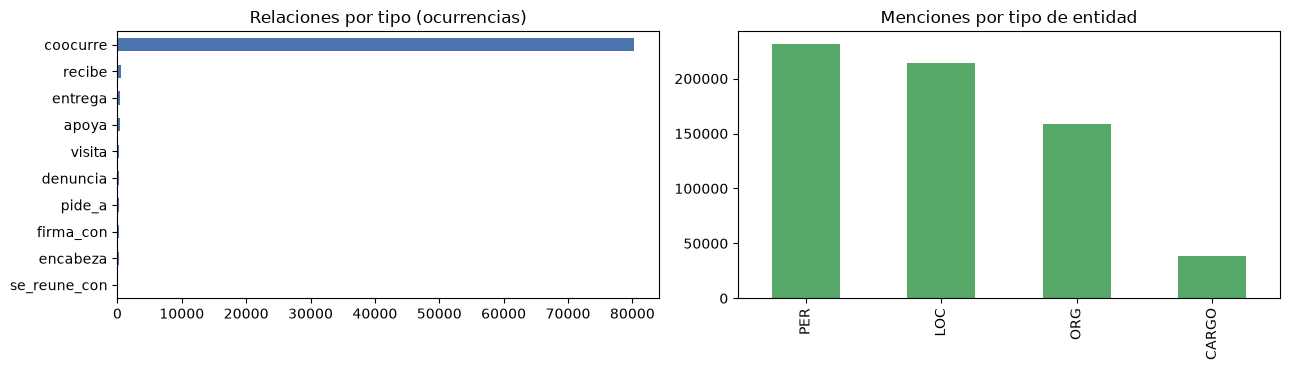

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
rel = pd.Series(stats["relaciones"]["por_tipo"]).head(10)[::-1]
rel.plot(kind="barh", ax=axes[0], color="#4c72b0")
axes[0].set_title("Relaciones por tipo (ocurrencias)")
axes[0].set_xlabel("")

por_tipo = pd.Series(stats["menciones"]["por_tipo"])
por_tipo.plot(kind="bar", ax=axes[1], color="#55a868")
axes[1].set_title("Menciones por tipo de entidad")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

In [13]:
for c in stats["grafo"]["comunidades_top"][:4]:
    print(f"comunidad {c['id']} ({c['tamano']} nodos): {', '.join(c['miembros'])}")

comunidad 0 (1045 nodos): canciller, embajador, fiscal general, juez, presidente, vicepresidente, Amazonia, America Latina
comunidad 1 (859 nodos): gobernador, Agua Negra, Aguascalientes, Baja California, Campeche, Chiapas, Chihuahua, Ciudad de México
comunidad 2 (528 nodos): ministro, portavoz, Africa, Andalucía, Aragón, Asturias, Baleares, Barcelona
comunidad 3 (455 nodos): almirante, comandante, coordinador, secretario, subsecretario, Misiones, Toledo, ASA


### Del grafo a la figura

Con `graph.json` (nodos/aristas) se puede dibujar el vecindario de una entidad. Aquí, el entorno de
una figura central con las aristas más pesadas:

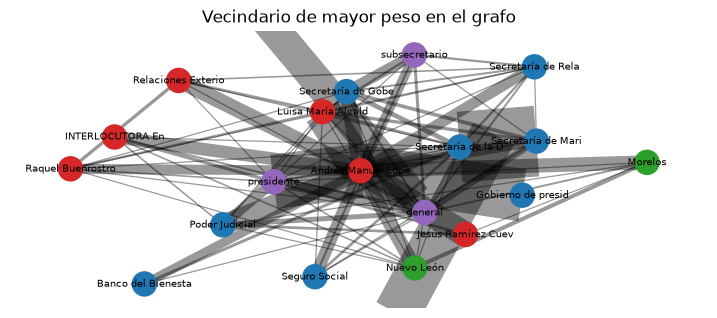

In [14]:
grafo = json.loads((config.ARTIFACTS / "graph.json").read_text(encoding="utf-8"))
G = nx.Graph()
for n in grafo["nodes"]:
    G.add_node(n["id"], type=n["type"], label=n["label"], mentions=n["mentions"])
for link in grafo["links"]:
    G.add_edge(link["source"], link["target"], weight=link["weight"], type=link["type"])

centro = "PER:Andrés Manuel López Obrador"
vecinos = sorted(G[centro].items(), key=lambda kv: -kv[1]["weight"])[:18]
H = G.subgraph([centro] + [v for v, _ in vecinos])
pos = nx.spring_layout(H, seed=7, k=0.6)
colores = {"PER": "#d62728", "ORG": "#1f77b4", "LOC": "#2ca02c", "CARGO": "#9467bd"}
nx.draw_networkx_nodes(H, pos, node_size=300,
                       node_color=[colores.get(H.nodes[n].get("type"), "#888") for n in H])
nx.draw_networkx_edges(H, pos, alpha=0.4,
                       width=[0.4 + 0.25 * H[u][v]["weight"] for u, v in H.edges()])
nx.draw_networkx_labels(H, pos, {n: H.nodes[n].get("label", n)[:18] for n in H}, font_size=7)
plt.axis("off")
plt.title("Vecindario de mayor peso en el grafo")
plt.show()

## 6. Evaluación

**Menciones.** Gold manual de 40 oraciones (8 por hablante) con 74 entidades etiquetadas a mano
(`er_scripts/gold/gold_sentences.csv`). Emparejamiento estricto por nodo canónico, con ablación
de coreferencia y con emparejamiento laxo.

**Relaciones.** Muestra de 53 aristas etiquetadas (`gold_relations.csv`): se juzga si las dos
entidades son correctas y si la oración de evidencia sostiene la relación. No hay recall de
relaciones: construir un gold exhaustivo excede el alcance del módulo.

Con muestras pequeñas se reporta el intervalo de Wilson al 95 %:
$\frac{\tilde p + z^2/2n \pm z\sqrt{\tilde p(1-\tilde p)/n + z^2/4n^2}}{1+z^2/n}$.

In [15]:
evaluacion = json.loads((config.ARTIFACTS / "eval.json").read_text(encoding="utf-8"))
print("gold:", evaluacion["gold"])
tabla = pd.DataFrame(evaluacion["menciones"]["por_tipo"]).T
tabla.loc["micro"] = evaluacion["menciones"]["micro"]
tabla[["tp", "fp", "fn", "precision", "recall", "f1"]]

gold: {'oraciones': 40, 'entidades': 74, 'por_tipo': {'ORG': 21, 'PER': 15, 'LOC': 38}}


,tp,fp,fn,precision,recall,f1
ORG,15,4,6,0.789,0.714,0.75
PER,12,2,3,0.857,0.8,0.828
LOC,31,0,7,1.0,0.816,0.899
micro,58,6,16,0.906,0.784,0.841


In [16]:
pd.DataFrame({k: v["micro"] for k, v in evaluacion["ablaciones"].items()}).T[
    ["tp", "fp", "fn", "precision", "recall", "f1"]]

,tp,fp,fn,precision,recall,f1
gazetteer + patrones + coref (estricto),58,6,16,0.906,0.784,0.841
sin coreferencia (estricto),57,6,17,0.905,0.77,0.832
con coreferencia (laxo),58,6,16,0.906,0.784,0.841


In [17]:
rel = evaluacion.get("relaciones") or {}
if rel:
    filas = [{"tipo": t, **v} for t, v in rel["por_tipo"].items() if v["n"] >= 3]
    filas += [{"tipo": t, **v} for t, v in rel.get("grupos", {}).items()]
    filas.append({"tipo": "total", "n": rel["n"], "aciertos": rel["aciertos"],
                  "precision": rel["precision"]})
    display(pd.DataFrame(filas))

,tipo,n,aciertos,precision
0,coocurre,30,21,0.700
1,verbales (todos los tipos),21,6,0.286
2,cargo (inferido/explícito),2,2,1.000
3,total,53,29,0.547


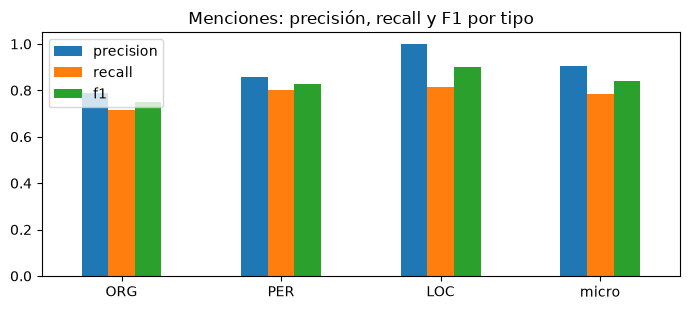

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.2))
t = pd.DataFrame(evaluacion["menciones"]["por_tipo"]).T[["precision", "recall", "f1"]].astype(float)
micro = evaluacion["menciones"]["micro"]
t.loc["micro"] = [micro["precision"], micro["recall"], micro["f1"]]
t[["precision", "recall", "f1"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title("Menciones: precisión, recall y F1 por tipo")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Limitaciones

* **Gold pequeño y de un solo anotador**: 40 oraciones y 74 entidades; los intervalos son anchos
  y las fronteras entre tipos son discutibles (`¿"Fuerzas Armadas" es ORG o un concepto?`).
* **El gold se revisó una vez** leyendo las oraciones completas (la muestra se había generado
  truncada a 400 caracteres). Esa pasada mejora la calidad del gold pero puede favorecer al
  sistema: se declara como sesgo de anotación.
* **Coreferencia acotada**: no hay resolución de pronombres personales lejanos (`él`, `ella`),
  ni desambiguación de homónimos, ni personas que ocupan el mismo cargo en fechas distintas: la
  tabla `CARGO_HOLDERS` es estática y por país.
* **Siglas**: se fusionan sólo si la expansión está en el diccionario; un acrónimo desconocido
  crea su propio nodo (`SAR`, `CESCOF`).
* **Relaciones verbales ruidosas**: precisión baja en la muestra (ver §6). El patrón
  sujeto–verbo–objeto elige la entidad más cercana, y en oraciones largas de transcripción la
  más cercana no siempre es el sujeto.
* **Coocurrencia no es relación semántica**: dice que dos entidades aparecen juntas, no qué las
  une. Sirve para explorar y para construir el grafo, no para afirmar hechos.
* **Cola larga**: 91 % de los nodos aparece en un solo documento; el grafo útil es el de los
  ~4 mil nodos conectados.

## 8. Reproducir

```bash
source ../env/bin/activate

python -m er_scripts.build_graph                   # 210 s → menciones, relaciones, grafo, stats
python -m er_scripts.build_graph --limit 200       # prueba rápida
python -m er_scripts.build_graph --no-coref --tag ablacion
python -m er_scripts.evaluate --markdown            # métricas + tablas
python -m er_scripts.evaluate --sample-relations 30 # muestra para etiquetar relaciones
```

Archivos del módulo: `config.py`, `lexicon.py`, `mentions.py`, `coref.py`, `relations.py`,
`graph.py`, `build_graph.py`, `evaluate.py`. Reporte completo en `er_scripts/doc_er.md`.